<div style='background-color: #E1F5FE; border-left:4px solid #2196F3; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Plotting: predicting flight ticket prices</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Team members: Nazar Zavrin, Oliver Albert Hallik, Kerreth Arula</strong></p>

</div>

This notebook creates plots for analysing relations between flight price and other properties, using features built in the notebook `feature_building_preprocessing.ipynb`.

While models can be useful for making predictions with higher accuracy, plots can help find potential relations simple enough for a person to consider manually, for example whether to choose a flight departing in the morning or evening for a likely cheaper price.

Means and medians help differentiate between cheap and expensive options, while lower standard deviation indicates that the low or high average price is more reliable.

**Input:** `features.parquet` (all 20M rows) for the plotting with the additional built features.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUT_FILE = Path.cwd() / "features.parquet"

In [4]:
df = pd.read_parquet(INPUT_FILE)

print("Loaded file:", INPUT_FILE.name)
print(df.shape)
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

Loaded file: features.parquet
(20381571, 32)
Memory usage: 2.25 GB


,itinerary_id,flight_number,price,log_price,split,price_outlier,price_datetime,departure_date,region_from,region_to,...,emissions_per_km,dep_hour,dep_weekday,dep_month,dep_is_weekend,is_christmas,is_new_year,is_summer,search_weekday,search_hour
0,FR8257-2025-05-03-RIX-PRG,FR8257,87.989998,4.477223,train,0,2025-05-02 22:58:11.409667,2025-05-03,Baltics,Eastern,...,93.433464,9,5,5,1,0,0,0,4,22
1,BT481-2025-05-03-RIX-PRG,BT481,159.320007,5.070915,train,0,2025-05-02 22:58:11.409719,2025-05-03,Baltics,Eastern,...,108.269150,18,5,5,1,0,0,0,4,22
2,LO794-2025-05-03-RIX-WAW,LO794,222.320007,5.404118,train,0,2025-05-02 22:58:11.409754,2025-05-03,Baltics,Eastern,...,126.946564,5,5,5,1,0,0,0,4,22
3,LO782-2025-05-03-RIX-WAW,LO782,222.320007,5.404118,train,0,2025-05-02 22:58:11.409798,2025-05-03,Baltics,Eastern,...,144.983139,18,5,5,1,0,0,0,4,22
4,BT611-2025-05-03-RIX-ATH,BT611,358.320007,5.881426,train,0,2025-05-02 22:58:11.409839,2025-05-03,Baltics,Eastern,...,94.131104,14,5,5,1,0,0,0,4,22


In [8]:
print(df.columns)

Index(['itinerary_id', 'flight_number', 'price', 'log_price', 'split',
       'price_outlier', 'price_datetime', 'departure_date', 'region_from',
       'region_to', 'is_best', 'airline', 'aircraft', 'src', 'dst',
       'departure_datetime', 'arrival_datetime', 'travel_time', 'emissions',
       'days_to_departure', 'distance_km', 'route', 'emissions_per_km',
       'dep_hour', 'dep_weekday', 'dep_month', 'dep_is_weekend',
       'is_christmas', 'is_new_year', 'is_summer', 'search_weekday',
       'search_hour'],
      dtype='str')


Plotting flight **prices** per **month**

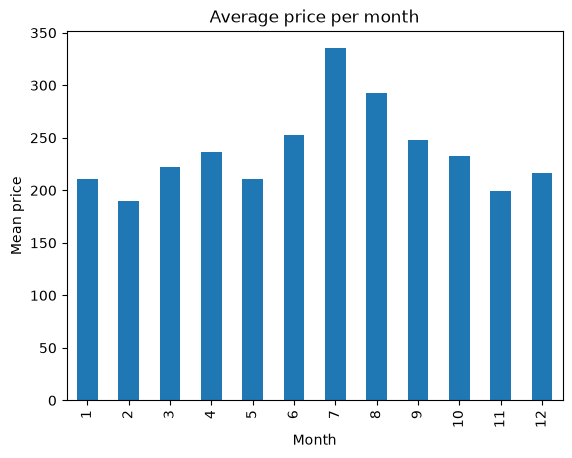

In [31]:
means_price_dep_month = df.groupby('dep_month')['price'].mean()

ax = means_price_dep_month.plot(kind="bar")
ax.set(title="Average price per month", xlabel="Month", ylabel="Mean price");

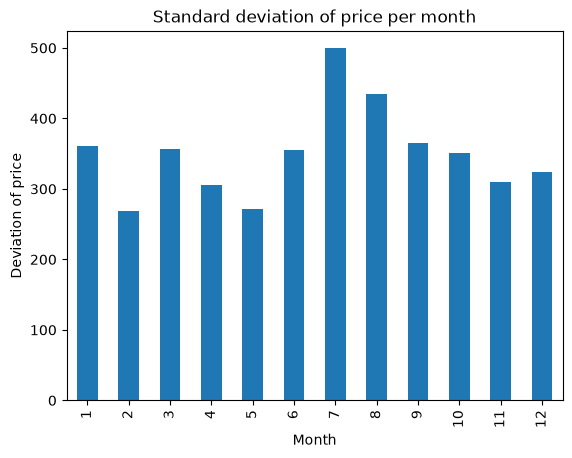

In [32]:
stddev_price_dep_month = df.groupby('dep_month')['price'].std()

ax = stddev_price_dep_month.plot(kind="bar")
ax.set(title="Standard deviation of price per month", xlabel="Month", ylabel="Deviation of price");

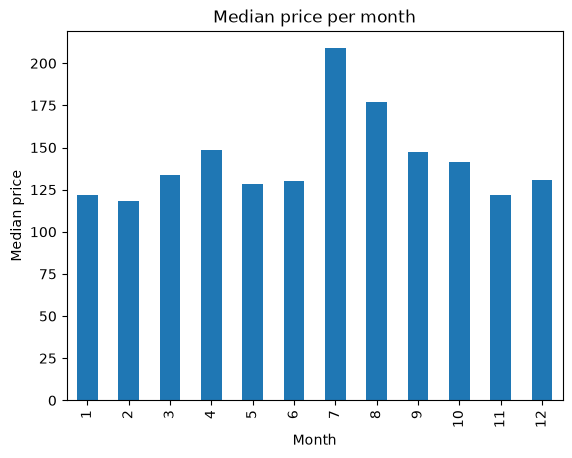

In [33]:
median_price_dep_month = df.groupby('dep_month')['price'].median()

ax = median_price_dep_month.plot(kind="bar")
ax.set(title="Median price per month", xlabel="Month", ylabel="Median price");

Plotting flight **prices** per **weekday**.

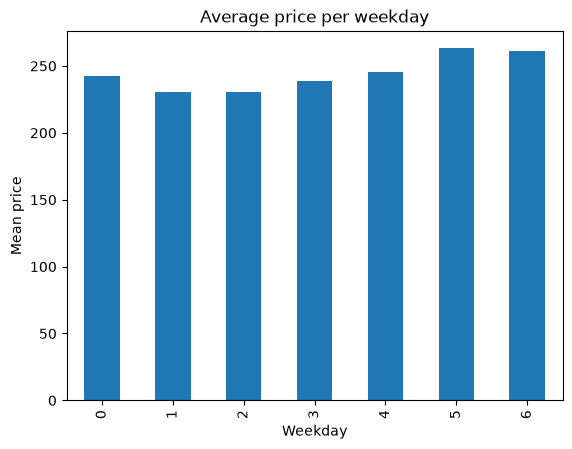

In [12]:
means_price_dep_weekday = df.groupby('dep_weekday')['price'].mean()

ax = means_price_dep_weekday.plot(kind="bar")
ax.set(title="Average price per weekday", xlabel="Weekday", ylabel="Mean price");

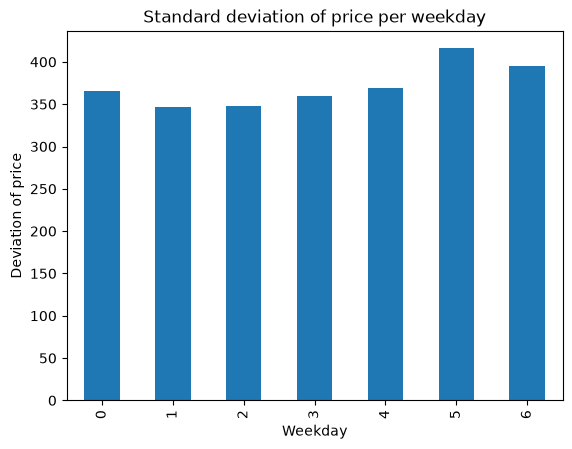

In [15]:
stddev_price_dep_weekday = df.groupby('dep_weekday')['price'].std()

ax = stddev_price_dep_weekday.plot(kind="bar")
ax.set(title="Standard deviation of price per weekday", xlabel="Weekday", ylabel="Deviation of price");

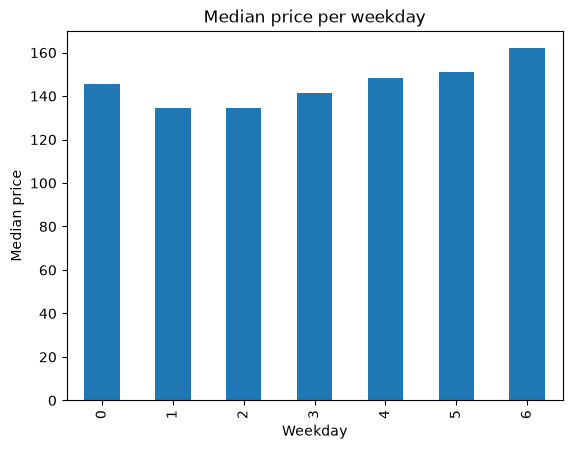

In [14]:
medians_price_dep_weekday = df.groupby('dep_weekday')['price'].median()

ax = medians_price_dep_weekday.plot(kind="bar")
ax.set(title="Median price per weekday", xlabel="Weekday", ylabel="Median price");

Flight prices by other built features

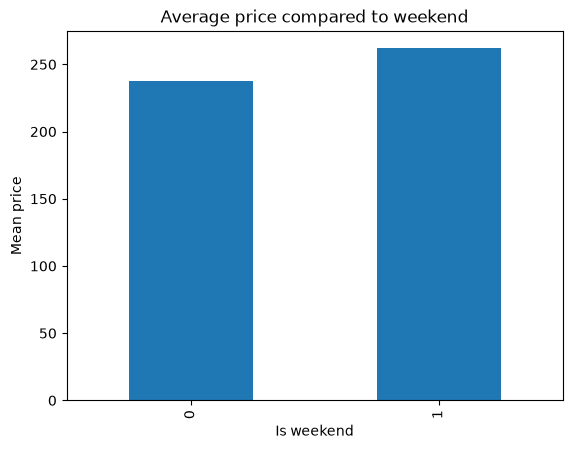

In [34]:
means_price_dep_weekend = df.groupby('dep_is_weekend')['price'].mean()

ax = means_price_dep_weekend.plot(kind="bar")
ax.set(title="Average price compared to weekend", xlabel="Is weekend", ylabel="Mean price");

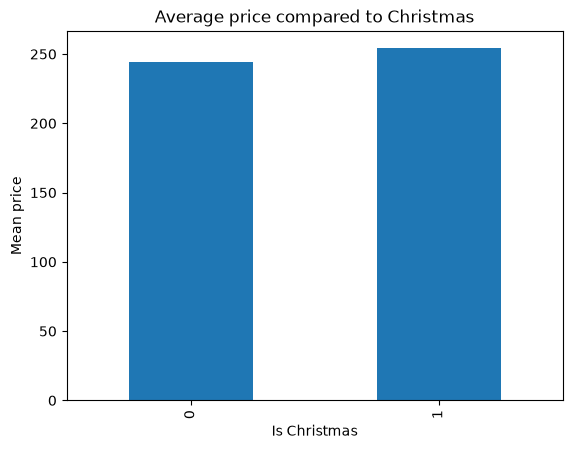

In [36]:
means_price_dep_christmas = df.groupby('is_christmas')['price'].mean()

ax = means_price_dep_christmas.plot(kind="bar")
ax.set(title="Average price compared to Christmas", xlabel="Is Christmas", ylabel="Mean price");

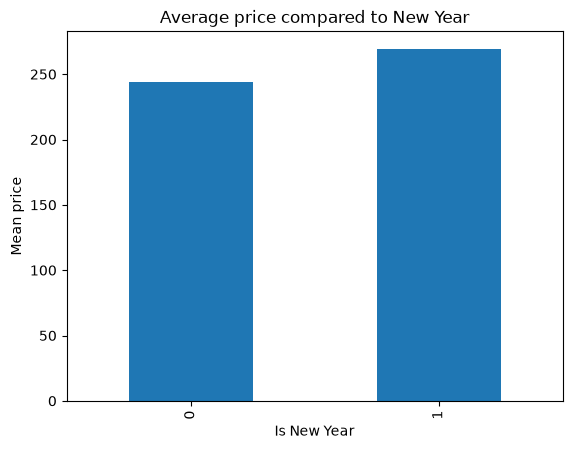

In [38]:
means_price_dep_new_year = df.groupby('is_new_year')['price'].mean()

ax = means_price_dep_new_year.plot(kind="bar")
ax.set(title="Average price compared to New Year", xlabel="Is New Year", ylabel="Mean price");

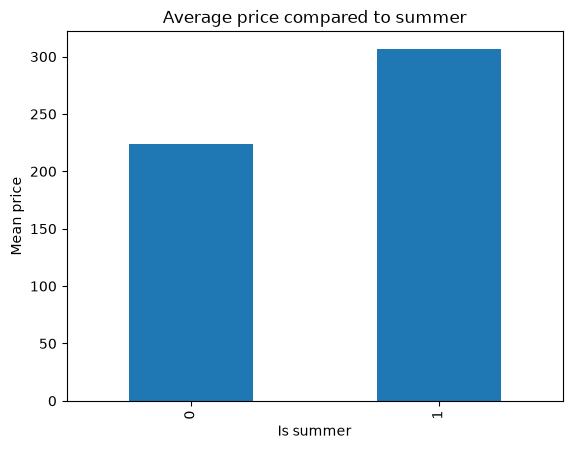

In [39]:
means_price_dep_summer = df.groupby('is_summer')['price'].mean()

ax = means_price_dep_summer.plot(kind="bar")
ax.set(title="Average price compared to summer", xlabel="Is summer", ylabel="Mean price");

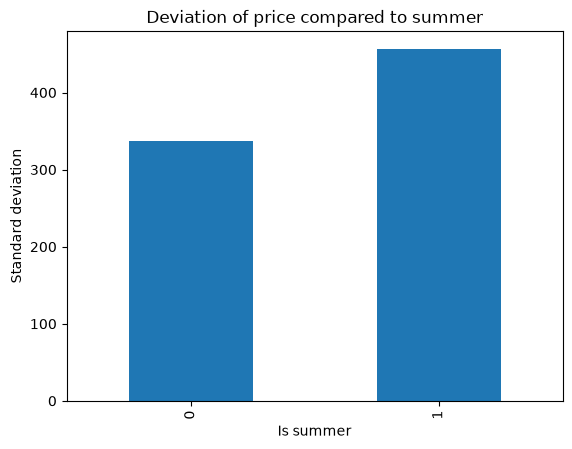

In [46]:
stddev_price_dep_summer = df.groupby('is_summer')['price'].std()

ax = stddev_price_dep_summer.plot(kind="bar")
ax.set(title="Deviation of price compared to summer", xlabel="Is summer", ylabel="Standard deviation");

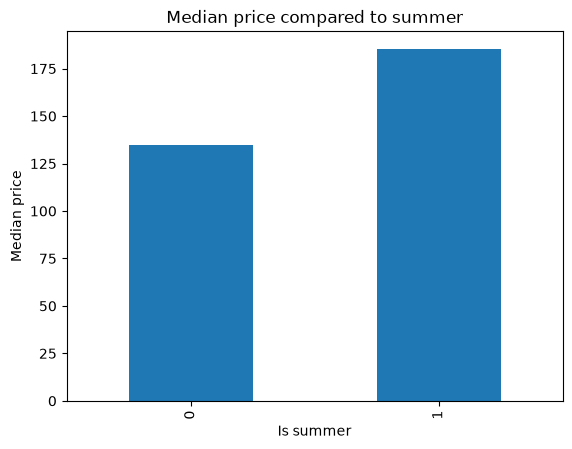

In [47]:
median_price_dep_summer = df.groupby('is_summer')['price'].median()

ax = median_price_dep_summer.plot(kind="bar")
ax.set(title="Median price compared to summer", xlabel="Is summer", ylabel="Median price");

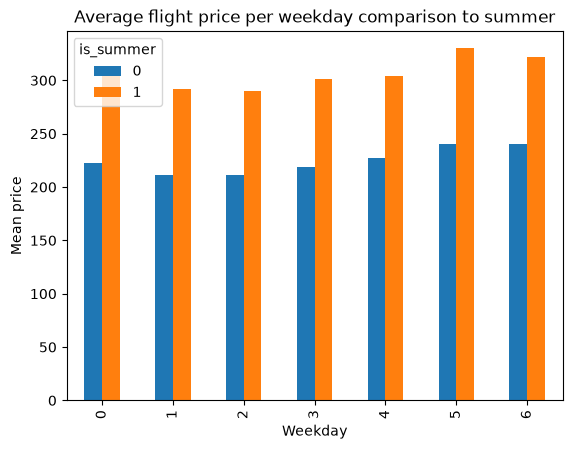

In [51]:
means_grouped_price_dep_weekday_is_summer = (
    df.groupby(["dep_weekday", "is_summer"])["price"]
    .mean()
    .unstack(fill_value=0)
)
ax = means_grouped_price_dep_weekday_is_summer.plot(kind="bar")
ax.set(title="Average flight price per weekday comparison to summer", xlabel="Weekday", ylabel="Mean price");

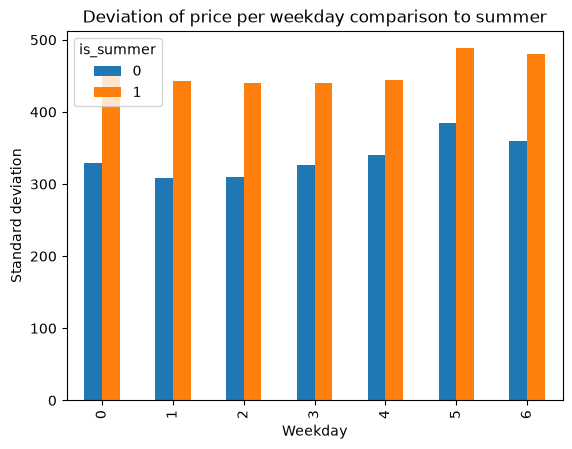

In [52]:
stddev_grouped_price_dep_weekday_is_summer = (
    df.groupby(["dep_weekday", "is_summer"])["price"]
    .std()
    .unstack(fill_value=0)
)
ax = stddev_grouped_price_dep_weekday_is_summer.plot(kind="bar")
ax.set(title="Deviation of price per weekday comparison to summer", xlabel="Weekday", ylabel="Standard deviation");

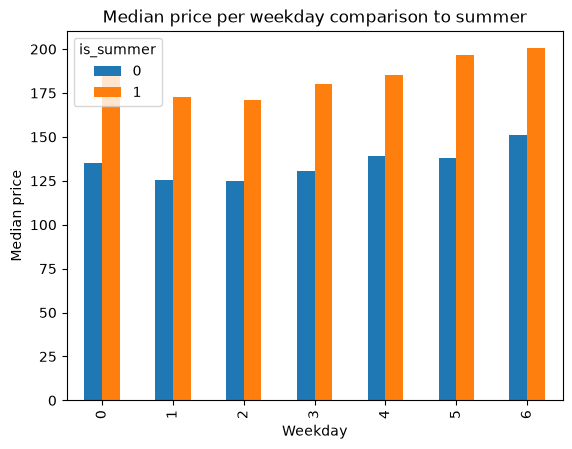

In [53]:
median_grouped_price_dep_weekday_is_summer = (
    df.groupby(["dep_weekday", "is_summer"])["price"]
    .median()
    .unstack(fill_value=0)
)
ax = median_grouped_price_dep_weekday_is_summer.plot(kind="bar")
ax.set(title="Median price per weekday comparison to summer", xlabel="Weekday", ylabel="Median price");

Flight **prices** by departure time **hour**

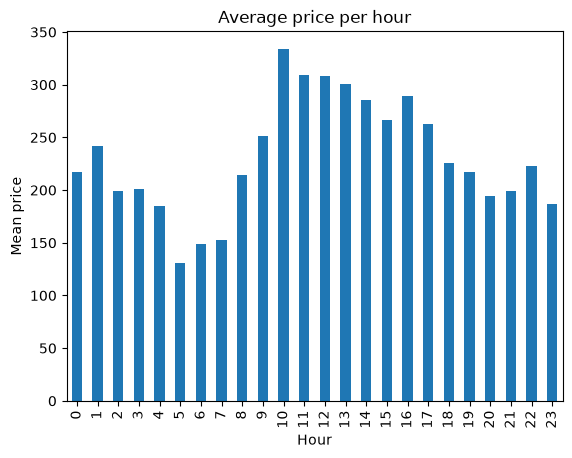

In [16]:
means_price_dep_hour = df.groupby('dep_hour')['price'].mean()

ax = means_price_dep_hour.plot(kind="bar")
ax.set(title="Average price per hour", xlabel="Hour", ylabel="Mean price");

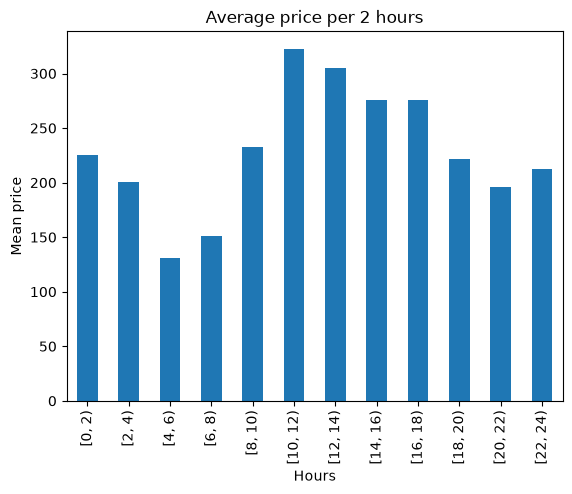

In [12]:
means_price_dep_2_hour = df.groupby(pd.cut(df['dep_hour'], [0,2,4,6,8,10,12,14,16,18,20,22,24], right=False))['price'].mean()

ax = means_price_dep_2_hour.plot(kind="bar")
ax.set(title="Average price per 2 hours", xlabel="Hours", ylabel="Mean price");

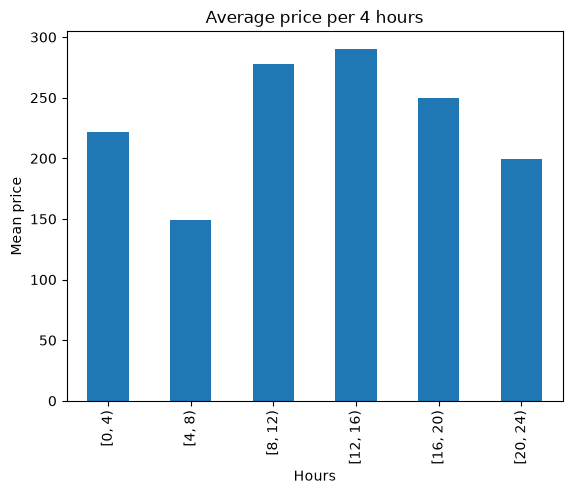

In [13]:
means_price_dep_4_hour = df.groupby(pd.cut(df['dep_hour'], [0,4,8,12,16,20,24], right=False))['price'].mean()

ax = means_price_dep_4_hour.plot(kind="bar")
ax.set(title="Average price per 4 hours", xlabel="Hours", ylabel="Mean price");

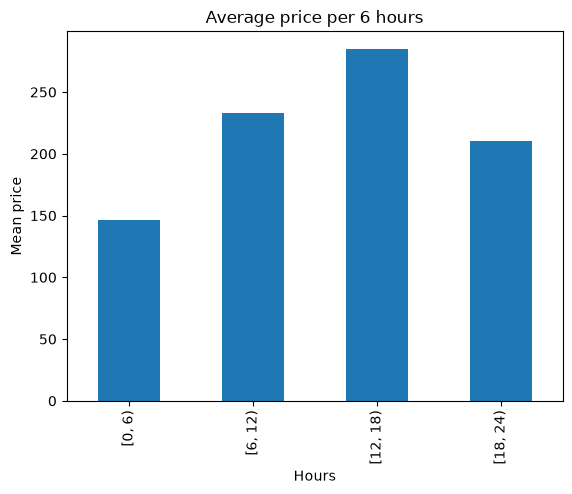

In [14]:
means_price_dep_6_hour = df.groupby(pd.cut(df['dep_hour'], [0,6,12,18,24], right=False))['price'].mean()

ax = means_price_dep_6_hour.plot(kind="bar")
ax.set(title="Average price per 6 hours", xlabel="Hours", ylabel="Mean price");

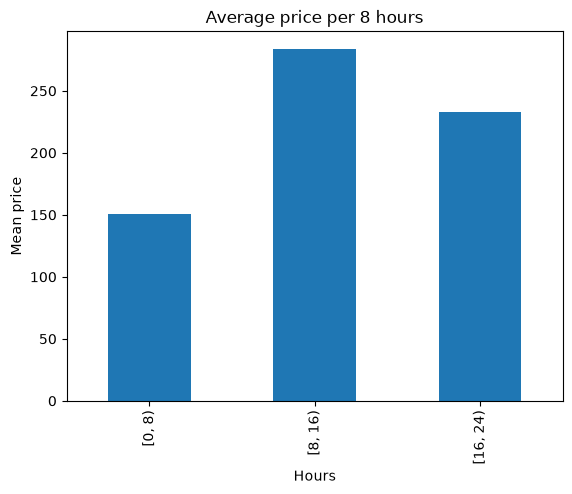

In [15]:
means_price_dep_8_hour = df.groupby(pd.cut(df['dep_hour'], [0,8,16,24], right=False))['price'].mean()

ax = means_price_dep_8_hour.plot(kind="bar")
ax.set(title="Average price per 8 hours", xlabel="Hours", ylabel="Mean price");

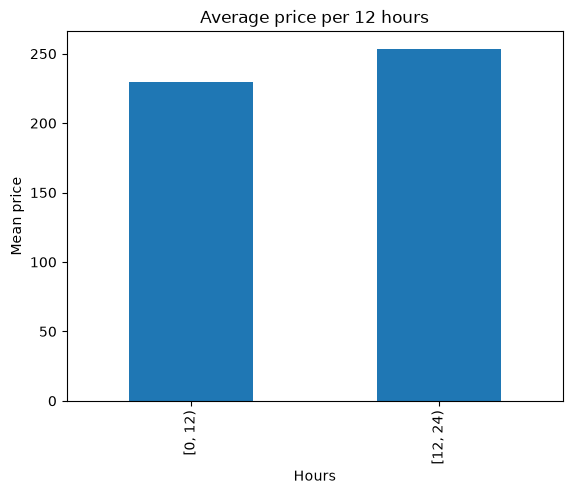

In [7]:
means_price_dep_12_hour = df.groupby(pd.cut(df['dep_hour'], [0,12,24], right=False))['price'].mean()

ax = means_price_dep_12_hour.plot(kind="bar")
ax.set(title="Average price per 12 hours", xlabel="Hours", ylabel="Mean price");

Flight **price** by departure time, per **4 hour** intervals

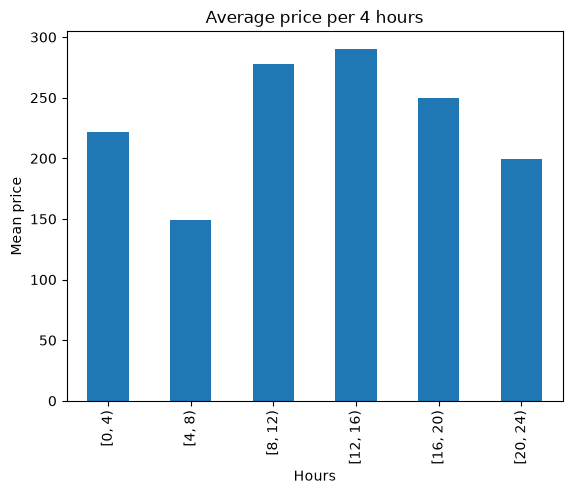

In [17]:
means_price_dep_4_hour = df.groupby(pd.cut(df['dep_hour'], [0,4,8,12,16,20,24], right=False))['price'].mean()

ax = means_price_dep_4_hour.plot(kind="bar")
ax.set(title="Average price per 4 hours", xlabel="Hours", ylabel="Mean price");

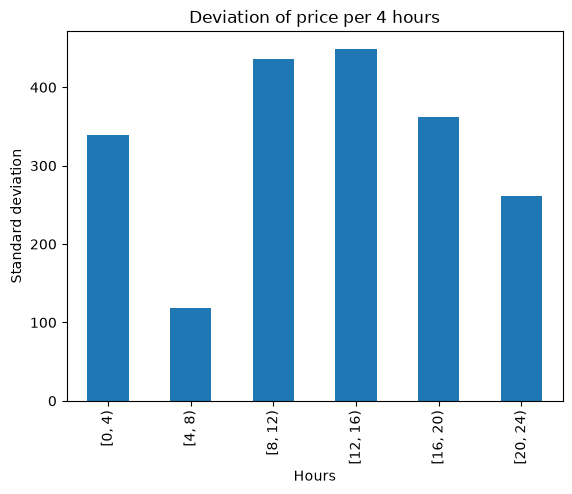

In [45]:
stddev_price_dep_4_hour = df.groupby(pd.cut(df['dep_hour'], [0,4,8,12,16,20,24], right=False))['price'].std()

ax = stddev_price_dep_4_hour.plot(kind="bar")
ax.set(title="Deviation of price per 4 hours", xlabel="Hours", ylabel="Standard deviation");

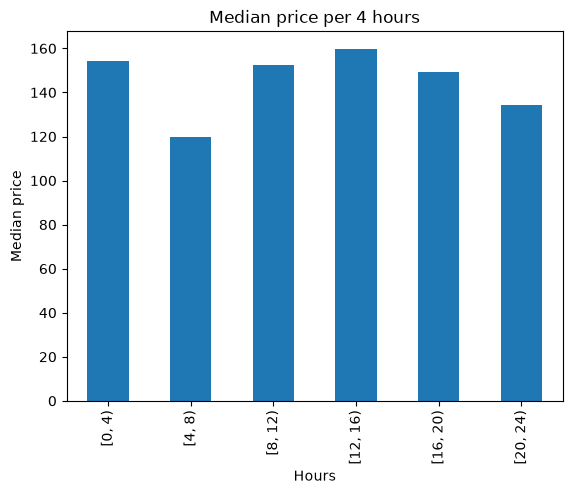

In [19]:
median_price_dep_4_hour = df.groupby(pd.cut(df['dep_hour'], [0,4,8,12,16,20,24], right=False))['price'].median()

ax = median_price_dep_4_hour.plot(kind="bar")
ax.set(title="Median price per 4 hours", xlabel="Hours", ylabel="Median price");

During hours 4, 5, 6 and 7, the price is generally lower and the price being cheaper at that time is more reliable according to the lower standard deviation. These graphs indicate that it is optimal to choose flights with departure starting at 04:00 and before 08:00 in the morning. Flights departing at other times generally cost more and higher standard deviation also indicates existence significantly more above average expensive outliers.

Flight **prices** per **airline**

In [9]:
means_price_airline = df.groupby('airline')['price'].mean()
stddev_price_airline = df.groupby('airline')['price'].std()
median_price_airline = df.groupby('airline')['price'].median()

sorted_price_airline = pd.DataFrame({'means':means_price_airline, 'stddev':stddev_price_airline, 'median':median_price_airline})
sorted_price_airline = sorted_price_airline.sort_values(by=['means']) # Sort all plots by means, so the order stays the same across different plots instead of rearranging by sorting again.

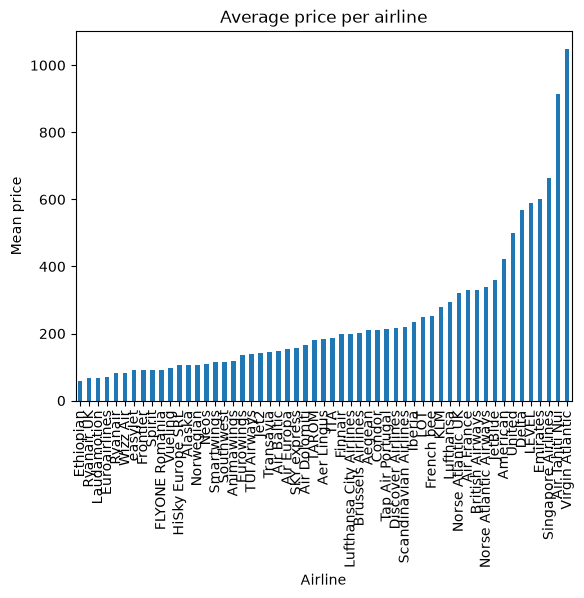

In [42]:
means_price_airline = sorted_price_airline['means']

ax = means_price_airline.plot(kind="bar")
ax.set(title="Average price per airline", xlabel="Airline", ylabel="Mean price");

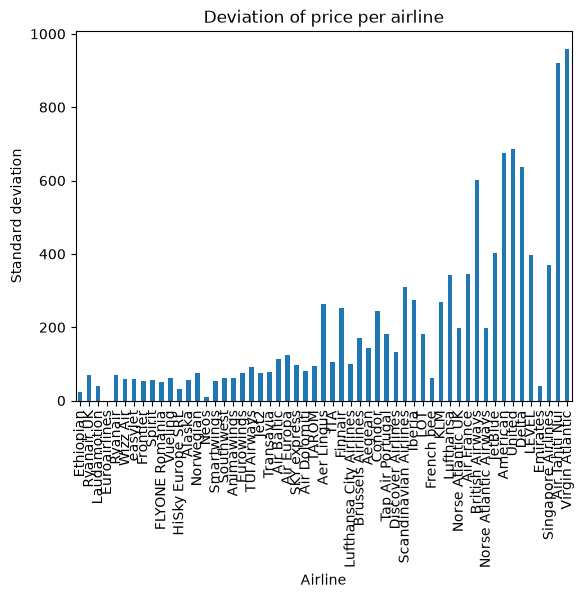

In [10]:
stddev_price_airline = sorted_price_airline['stddev'] # Keep sorted by means, it is more important to find the airline corresponding to one seen in the means plot, instead of finding airlines with less or more fluctuating prices ignoring whether they are generally cheap or expensive.

ax = stddev_price_airline.plot(kind="bar")
ax.set(title="Deviation of price per airline", xlabel="Airline", ylabel="Standard deviation");

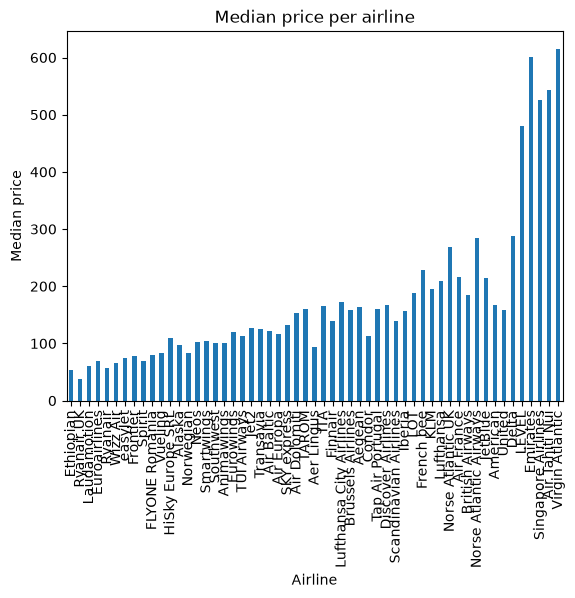

In [44]:
median_price_airline = sorted_price_airline['median']

ax = median_price_airline.plot(kind="bar")
ax.set(title="Median price per airline", xlabel="Airline", ylabel="Median price");

Scatterplot of prices by travel distance and scatterplot of prices by emissions

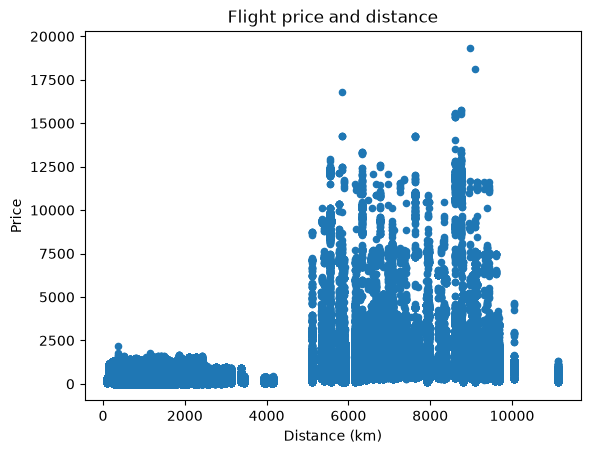

In [5]:
ax = df.plot(x="distance_km", y="price", kind="scatter")
ax.set(title="Flight price and distance", xlabel="Distance (km)", ylabel="Price");

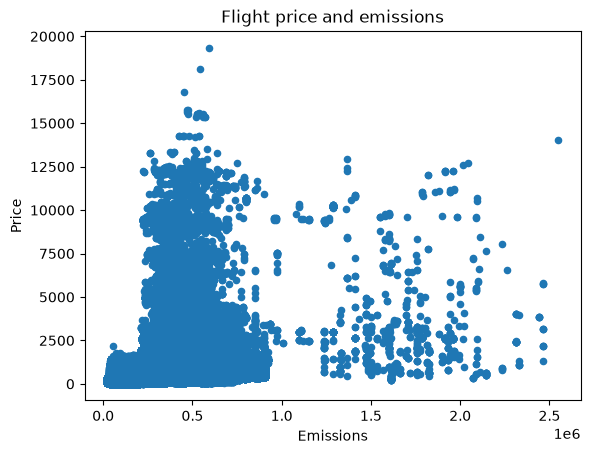

In [6]:
ax = df.plot(x="emissions", y="price", kind="scatter")
ax.set(title="Flight price and emissions", xlabel="Emissions", ylabel="Price");

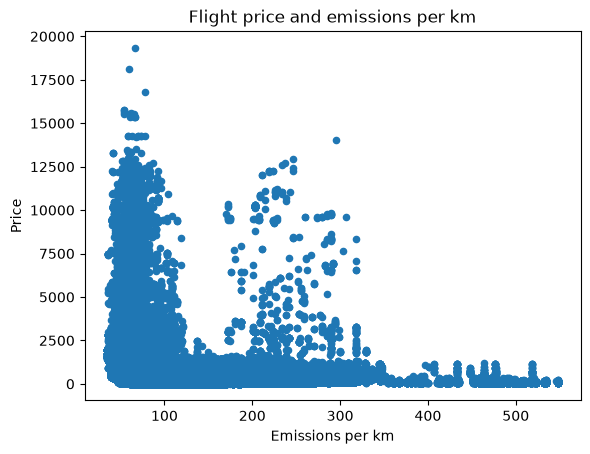

In [11]:
ax = df.plot(x="emissions_per_km", y="price", kind="scatter")
ax.set(title="Flight price and emissions per km", xlabel="Emissions per km", ylabel="Price");